**Loading libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

**Define the map from set to integer**

In [2]:
n_strains = 11
n_classes = 2**n_strains

def int2set(index, n_strains):
    history_set = set()
    for i in range(n_strains):
        if index & (1 << i):
            history_set.add(i + 1)
    return history_set

def set2int(strain_set):
    index = 0
    for strain in strain_set:
        index |= (1 << (strain - 1))
    return index

def int2string(index, n_strains):
    if index == 0:
        return "{0}"
    strain_list = sorted(int2set(index, n_strains))
    return "{" + ",".join(map(str, strain_list)) + "}"

def history_classes(n_strains):
    n_classes = 2**n_strains
    for i in range(n_classes):
        set_rep = int2set(i, n_strains)
        string_rep = int2string(i, n_strains)
        print(f"Index {i:2d}: {string_rep} = {set_rep}")

#history_classes(n_strains)

**Define cross-reactivity matrix**

In [3]:
epsilon_value = 0.2

def sigma_matrix(n_strains: int,
                 mode: str = "exp",
                 epsilon: float = epsilon_value):

    n_classes = 2**n_strains
    sigma = np.zeros((n_classes, n_strains), dtype=float)

    max_dist = max(1, n_strains - 1)

    for J in range(n_classes):
        H = int2set(J, n_strains)
        for i1 in range(1, n_strains + 1):
            if not H:
                sigma_val = 1.0
            elif i1 in H:
                sigma_val = 0.0
            else:
                dist = min(abs(i1 - j) for j in H)
                if mode == "normalized":
                    sigma_val = 1.0 - (dist / max_dist)
                elif mode == "exp":
                      sigma_val = 1.0 - (epsilon ** dist)
                else:
                      raise ValueError("mode must be normalized or exp")
            sigma[J, i1 - 1] = max(0.0, min(1.0, sigma_val))

    return sigma

sig_matrix = sigma_matrix(n_strains, mode="exp", epsilon=epsilon_value)
print(sig_matrix)


[[1.         1.         1.         ... 1.         1.         1.        ]
 [0.         0.8        0.96       ... 0.99999744 0.99999949 0.9999999 ]
 [0.8        0.         0.8        ... 0.9999872  0.99999744 0.99999949]
 ...
 [0.         0.8        0.         ... 0.         0.         0.        ]
 [0.8        0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


**Constructing system**

In [4]:
def construct_sys(n_strains: int, beta_vec, gamma_vec, mu, N, sigma):
    n_classes = 2**n_strains
    eligible = np.zeros((n_strains, n_classes), dtype=bool)
    for i in range(n_strains):
        for J in range(n_classes):
            eligible[i, J] = (((J >> i) & 1) == 0)

    def rhs(t, y):
        dy = np.zeros_like(y)
        S = y[:n_classes]
        I = y[n_classes:].reshape(n_strains, n_classes)

        I_tot = I.sum(axis=1)
        Lambda = beta_vec * (I_tot / N)

        #S compartment
        for J in range(n_classes):
            H = int2set(J, n_strains)

            births = mu * N if J == 0 else 0.0

            inf_out = 0.0
            for i in range(n_strains):
                if eligible[i, J]:
                    inf_out += sigma[J, i] * Lambda[i] * S[J]

            rec_in = 0.0
            for i in range(n_strains):
                if (i+1) in H:
                    K = set(H); K.remove(i+1)
                    rec_in += gamma_vec[i] * I[i, set2int(K)]
            dy[J] = births + rec_in - inf_out - mu*S[J]

        #I compartment
        for i in range(n_strains):
            for J in range(n_classes):
                idx = n_classes + i*n_classes + J
                if eligible[i, J]:
                    infection = sigma[J, i] * Lambda[i] * S[J]
                    removal   = (mu + gamma_vec[i]) * I[i, J]
                    dy[idx] = infection - removal
                else:
                    dy[idx] = -mu * I[i, J]
        return dy

    return rhs

**Define the seed**

In [5]:
def seed_strain(y, n_strains, strain_index, eps_seed):
    n_classes = 2**n_strains
    S = y[:n_classes].copy()
    I = y[n_classes:].reshape(n_strains, n_classes).copy()

    s = strain_index - 1
    for J in range(n_classes):
        if ((J >> s) & 1) == 0:
            seed = eps_seed * S[J]
            if seed > 0:
                S[J] -= seed
                I[s, J] += seed

    return np.concatenate([S, I.ravel()])

**Run the system**

In [6]:
def vec(x, n):
    x = np.asarray(x, dtype=float)
    if x.size == 1:
        return np.full(n, float(x))
    if x.size != n:
        raise ValueError(f"Expected length {n}, got {x.size}")
    return x


def run_sys(n_strains, beta_vec, gamma_vec, mu, N, sigma, t0, T_end, y0, seed_events):
    beta_vec  = vec(beta_vec,  n_strains)
    gamma_vec = vec(gamma_vec, n_strains)
    rhs = construct_sys(n_strains, beta_vec, gamma_vec, mu, N, sigma)

    times = []
    states = []

    t_curr = t0
    y_curr = y0.copy()

    def append_solution(sol):
        if len(times) == 0:
            times.extend(sol.t.tolist())
            states.append(sol.y)
        else:
            times.extend(sol.t[1:].tolist())
            states.append(sol.y[:, 1:])

    for ev in sorted(seed_events, key=lambda e: e["t"]):
        t_next = float(ev["t"])
        if t_next <= t_curr:
            continue
        sol = solve_ivp(rhs, (t_curr, t_next), y_curr, method="RK45",
                        rtol=1e-7, atol=1e-9, max_step=0.5)
        append_solution(sol)
        y_curr = sol.y[:, -1]

        strain = int(ev["strain"])
        eps_seed = float(ev["eps_seed"])
        y_curr = seed_strain(y_curr, n_strains, strain, eps_seed)
        t_curr = t_next

    if t_curr < T_end:
        sol = solve_ivp(rhs, (t_curr, T_end), y_curr, method="RK45",
                        rtol=1e-7, atol=1e-9, max_step=0.5)
        append_solution(sol)

    Y = np.hstack(states)
    t = np.array(times)
    return t, Y


**Setting parameter values**

In [7]:
N = 100000
mu = 1/(70*365)
gamma = 1/7
gamma_vec = [gamma]*n_strains
beta_vec = [0.8, 0.85, 0.7, 0.6, 0.55, 0.5, 0.45, 0.4, 0.3, 0.2, 0.15]
sigma = sigma_matrix(n_strains)

n_classes = 2**n_strains
S0 = np.zeros(n_classes); S0[0] = N - 1.0
I0 = np.zeros((n_strains, n_classes))
I0[0, 0] = 1.0
y0 = np.concatenate([S0, I0.ravel()])

seed_events = [
    {"t": 60.0, "strain": 2, "eps_seed": 2e-5},
    {"t": 100.0, "strain": 3, "eps_seed": 2e-5},
    {"t": 120.0, "strain": 4, "eps_seed": 2e-5},
    {"t": 200.0, "strain": 5, "eps_seed": 2e-5},
    {"t": 220.0, "strain": 6, "eps_seed": 2e-5},
    {"t": 280.0, "strain": 7, "eps_seed": 2e-5},
    {"t": 320.0, "strain": 8, "eps_seed": 2e-5},
    {"t": 360.0, "strain": 9, "eps_seed": 2e-5},
    {"t": 400.0, "strain": 10, "eps_seed": 2e-5},
    {"t": 450.0, "strain": 11, "eps_seed": 2e-5},

]

t0 = 0.0
T_end = 800.0

**Calculating prevalence classes and proportion of each strain**

In [8]:
t, Y = run_sys(
    n_strains=n_strains,
    beta_vec=beta_vec,
    gamma_vec=gamma_vec,
    mu=mu,
    N=N,
    sigma=sigma,
    t0=t0,
    T_end=T_end,
    y0=y0,
    seed_events=seed_events
)

I_all = Y[n_classes:, :].reshape(n_strains, n_classes, len(t))
I_tot_by_strain = I_all.sum(axis=1)
I_tot = I_tot_by_strain.sum(axis=0)
prev = I_tot_by_strain / N
prop = I_tot_by_strain / I_tot

**Calculating R0 (basic reproduction number) for each strain**

In [9]:
mu = 1/(70*365)
gamma_vec = np.array(gamma_vec)
beta_vec  = np.array([beta_vec]).ravel()

R0 = beta_vec / (gamma_vec + mu)
print("R0 for each strain:")
print(R0)

R0 for each strain:
[5.59846617 5.94837031 4.8986579  4.19884963 3.84894549 3.49904136
 3.14913722 2.79923309 2.09942482 1.39961654 1.04971241]


**Plotting 11-strains dynamic**

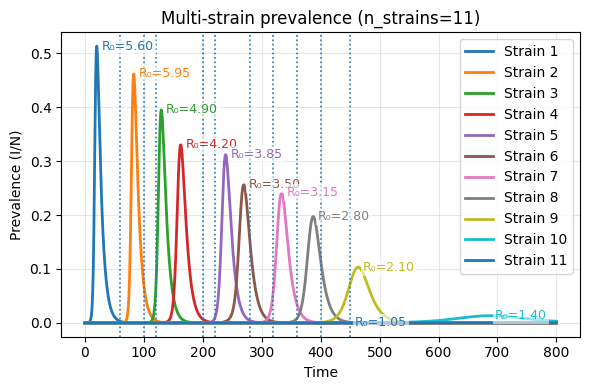

In [10]:
plt.figure(figsize=(6, 4))

for i in range(n_strains):
    line, = plt.plot(t, prev[i], label=f"Strain {i+1}", linewidth=2.0)

    peak_idx = np.argmax(prev[i])
    peak_t = t[peak_idx]
    peak_y = prev[i][peak_idx]

    plt.text(
        peak_t + 8,
        peak_y,
        f"R₀={R0[i]:.2f}",
        color=line.get_color(),
        fontsize=9,
        fontweight='normal',
        ha='left',
        va='center',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1.5)
    )

for ev in seed_events:
    plt.axvline(ev["t"], linestyle=":", linewidth=1.2)

plt.xlabel("Time")
plt.ylabel("Prevalence (I/N)")
plt.title(f"Multi-strain prevalence (n_strains={n_strains})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**11-strains replacement proportion**

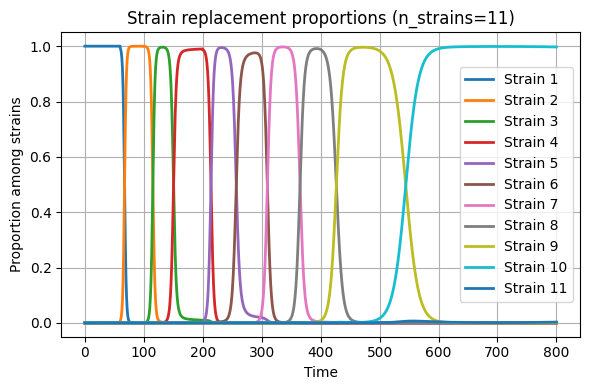

In [11]:
plt.figure(figsize=(6,4))
for i in range(n_strains):
    plt.plot(t, prop[i], label=f"Strain {i+1}", linewidth=2.0)

plt.title(f"Strain replacement proportions (n_strains={n_strains})")
plt.xlabel("Time"); plt.ylabel("Proportion among strains"); plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()
